# 03 · Can time preferences be shaped? Framing, magnitude and a text pilot

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/academic-research/time-preference-choice-models/notebooks/03_framing_effect_and_text_pilot.ipynb)

Calendar dates instead of delays (Read et al. 2005) are a cheap intervention. This notebook
estimates its effect with a permutation test and a bootstrap, checks the magnitude effect within
participants, and then pilots a second data source: everyday text about money.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "academic-research/time-preference-choice-models"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "timepref").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: time-preference-choice-models


In [2]:
from timepref import config as C, data, quality as Q, models as M, evaluate as E, effects as F, nlp as N, reporting as R

if not (Path("data") / "trials.csv.gz").exists():
    data.save(data.generate(), Path("data"))
tables = data.load(Path("data"))
clean, quality_log, rules = Q.apply(tables)
print(f"{clean['pid'].nunique()} participants, {len(clean):,} choices after exclusions")
fits = M.fit_all(clean, models=("hyperbolic", "quasi_hyperbolic"))
people = F.person_table(clean, fits)

399 participants, 23,940 choices after exclusions


## The framing effect

The outcome is each participant's fitted hyperbolic log k, plus two others: the model-free share of
later choices and the present-bias parameter beta.

In [3]:
framing = F.framing_effect(people)
framing.round(3)

,outcome,diff,ci_low,ci_high,p_perm,cohens_d,n_date,n_delay
0,log_k,-0.819,-1.023,-0.616,0.0,-0.755,199,200
1,share_later,0.132,0.095,0.167,0.0,0.719,199,200
2,beta,0.079,0.052,0.105,0.0,0.572,199,200


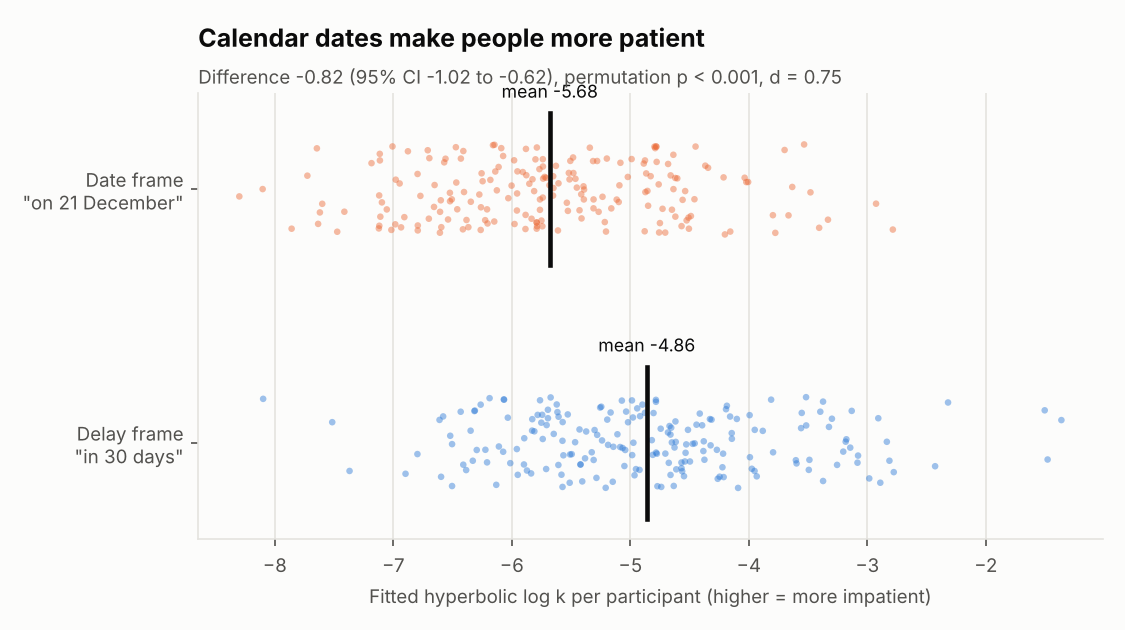

In [4]:
R.plot_framing(people, framing, Path("outputs/figures/framing_effect.png"))
display(Image("outputs/figures/framing_effect.png"))

The estimated drop in log k (about 0.8) is larger than the factor built into the simulation for
discounters (0.5). Heuristic users react to the frame too, and a hyperbolic fit expresses their
change as a change in k. The share of later choices does not depend on any model, which is why it
should be reported alongside k.

Does the result depend on the exclusions? Barely:

In [5]:
excluded = sorted(set(rules[1].flagged) | set(rules[2].flagged))
F.with_careless(tables["trials"].query("submission == 1"), None, excluded).round(3)

,sample,diff,ci_low,ci_high,p_perm,cohens_d,n_date,n_delay
0,after exclusions,0.132,0.100,0.168,0.0,0.719,199,200
1,no exclusions,0.126,0.091,0.163,0.0,0.675,209,207


## The magnitude effect

Each person's k is fitted twice, once on later amounts below 70 euros and once above. Larger amounts
should be discounted less (Kirby and Maraković 1996).

In [6]:
mag = F.magnitude_effect(clean)
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in mag.items() if k != "table"}

{'cut_eur': 70.0, 'mean_diff_log_k': -0.502, 'median_diff_log_k': -0.345, 'ci_low': -0.594, 'ci_high': -0.412, 'p_signflip': 0.0, 'share_lower_k_for_large': 0.749, 'n': 399}

## Text pilot: future orientation in everyday posts

Fifteen thousand fictional posts about money, spread over a year, with a dip around Black Friday and
in December and a rise after New Year built in. Two simulated annotators label 900 of them. Then a
classifier is trained and tested two ways: on a random split, and holding out whole phrasings, as
happens when language moves on after the labels were made.

In [7]:
posts = N.simulate_posts()
posts["posts"].sample(6, random_state=3)[["week", "text", "true_label"]]

,week,text,true_label
4491,2026-04-20,"black friday got me again, laptop in the basket",present
9137,2025-12-08,"honestly can't be bothered to budget, ordered the concert tickets 🙃",present
13085,2026-09-14,why wait? got the game console right now,present
6307,2026-09-14,Anyone know a good bank for students in berlin,neutral
7175,2026-08-03,is the phone worth 30 or overpriced,neutral
4995,2026-09-14,"slowly building retirement, 30 at a time 🙃",future


In [8]:
text = N.evaluate_text(posts["annotations"])
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in text.items() if k not in ("confusion", "model")}

{'kappa_annotators': 0.76, 'agreement_annotators': 0.841, 'gold_accuracy_vs_truth': 0.988, 'f1_random_split': 0.956, 'f1_grouped_cv': 0.508, 'f1_lexicon': 0.652, 'n_labelled': 900}

The random split says 0.96; holding out phrasings says about 0.5. The second number is the one to
believe for new data. Even so, the weekly index built from the classifier follows the truth well,
because errors average out over a few hundred posts a week.

In [9]:
N.accuracy_by_phrasing(posts["posts"], text)

,phrasing,posts,accuracy
0,mixed (two clauses),1114.0,0.607720
1,new since labelling,4155.0,0.629362
2,seen in labelling,9731.0,1.000000


classifier: r = 0.932
   lexicon: r = 0.838


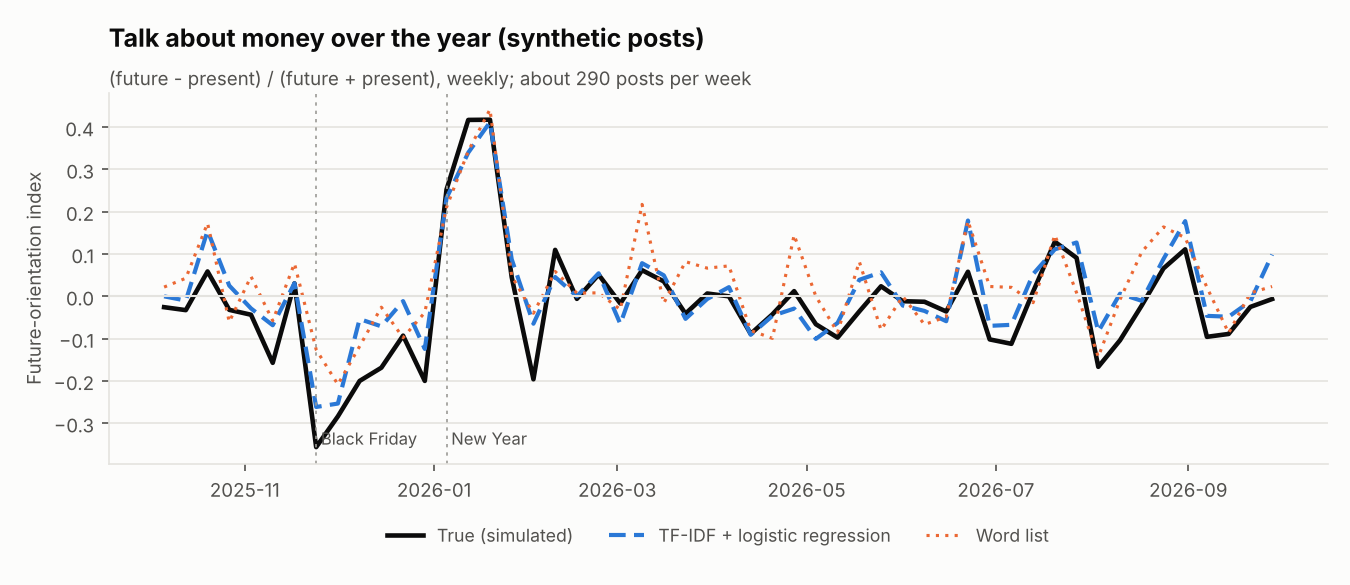

In [10]:
weekly = N.weekly_index(posts["posts"], text)
for c in ("classifier", "lexicon"):
    print(f"{c:>10}: r = {np.corrcoef(weekly[c + '_index'], weekly['true_index'])[0, 1]:.3f}")
R.plot_weekly(weekly, Path("outputs/figures/future_orientation_index.png"))
display(Image("outputs/figures/future_orientation_index.png"))

## From here to the paper

The draft in `paper/paper.pdf` writes these results up, and `docs/literature_review.md` maps the
research they build on. With real social-media data the same steps apply, plus an ethics review and
GDPR safeguards: only public posts, pseudonymised authors and aggregated reporting.